# **MCMC: Álgoritmo de Metrópolis**
Elaborado por: Jorge Luis Magaña Pichardo

In [2]:
import random as r
import matplotlib.pyplot as plt
import numpy as np

Usamos el algoritmo metropolis hastings, cuyo pseudocódigo está dado por:

![Metropolis](Metropolis-1.png)

Donde la función $q(\cdot | X_t)$ es una distribución que ya se sepa simular (por su simetría, suele elegirse la distribución normal para facilitar el proceso de simulación), $\pi(\cdot)$ es la función objetivo, es decir $f(\cdot)$, y $\alpha(X_t, Y)$, la probabilidad de aceptación, está definida como:

$$
\alpha(X, Y) = \min \left( 1, \frac{\pi(Y) q(X | Y)}{\pi(X) q(Y | X)} \right)
$$

Entonces para simular la normal, creamos la función

In [3]:
#Distibución normal
def normal(mu=0, sigma=1):
    return r.normalvariate(mu, sigma)

Usaremos el ejemplo dado en clase:

$$
f(x_1, x_2) = \frac{1}{20216.335877} \exp\left( - \left[ x_1^2 x_2^2 + x_1^2 + x_2^2 - 8x_1 - 8x_2 \right] \right)
$$


In [4]:
def f(x1,x2):
    exponente = -((x1**2)*(x2**2) + (x1**2) + (x2**2) - 8*x1 - 8*x2)
    return (1/20216.335877)*np.exp(exponente)

X1 y X2 son valores que en este código decidí dejar que el usuario ingrese cualquier par ordneado

In [5]:
def X_inicial():
    x1 = float(input("Ingrese el valor inicial: "))
    x2 = float(input("Ingrese el valor inicial: "))
    return (x1,x2)

Comienzo una función de caminata aleatoria basandome en el pseudocódigo

In [9]:
#caminata aleatoria
def caminata_aleatoria(n_iter, sigma=1.0):
    # Pedir el punto inicial al usuario
    X_t = list(X_inicial())
    
    # Lista para guardar todos los estados de la cadena
    muestras = [X_t]
    
    for t in range(1, n_iter):
        # Generar propuesta candidata Z ~ N(0, sigma)
        z1 = normal(0, sigma)
        z2 = normal(0, sigma)
        Z = [z1, z2]
        
        # Candidato Y = X_t + Z
        Y = [X_t[0] + Z[0], X_t[1] + Z[1]]
        
        # Probabilidad de aceptación
        f_y = f(Y[0], Y[1])
        f_x = f(X_t[0], X_t[1])
        
        a = min(f_y / f_x, 1) if f_x > 0 else 1.0
        
        # Criterio de aceptación/rechazo
        u = r.uniform(0, 1)
        if u < a:
            X_t = Y  # Aceptar propuesta
            
        # Guardar el estado en la lista
        muestras.append(X_t)
        
    return muestras

El número de iteraciones lo fije en 10000, y los números que use para mi ejemplo como usuario fueron 6 y 7

In [14]:
# Número de iteraciones
N = 10000

muestras = caminata_aleatoria(N, sigma=0.8)

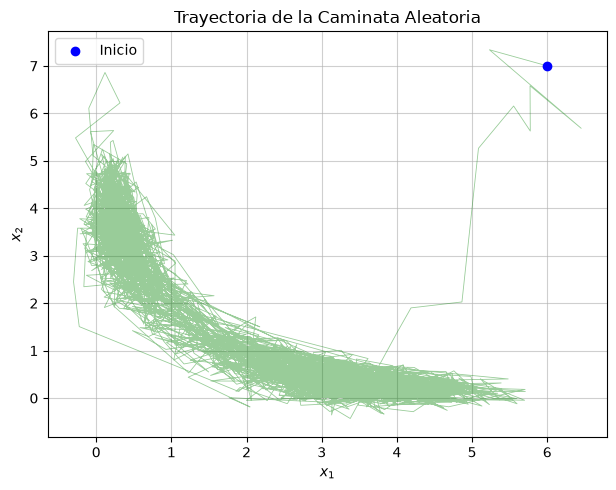

In [22]:
# Separar las coordenadas x1 y x2 de la lista de muestras
x1_vals = [punto[0] for punto in muestras]
x2_vals = [punto[1] for punto in muestras]

plt.figure(figsize=(12, 5))

# Gráfica 1: Trayectoria de la caminata aleatoria
plt.subplot(1, 2, 1)
plt.plot(x1_vals, x2_vals, alpha=0.4, linewidth=0.6, color='green')
plt.scatter(x1_vals[0], x2_vals[0], color='blue', label='Inicio', zorder=5)
plt.title("Trayectoria de la Caminata Aleatoria")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.grid(True, linestyle='-', alpha=0.6)
plt.legend()


plt.tight_layout()
plt.show()


La gráfica ilustra el recorrido secuencial realizado por la cadena de Markov a lo largo de las iteraciones en el espacio bidimensional $(x_1, x_2)$. 

* **Punto inicial:** El marcador resalta el par ordenado inicial $(x_1, x_2)$ que ingresé al comienzo de la simulación.
* **Trayectoria de estados:** Las líneas representan los transiciones sucesivas entre los estados aceptados $(X_t \to X_{t+1})$. 
* **Dinámica del algoritmo:** Permite observar la fase de exploración del algoritmo desde la condición inicial hacia las regiones de mayor densidad de probabilidad. La acumulación de trazos en zonas específicas evidencia la convergencia de la cadena hacia las regiones donde la función de densidad objetivo $f(x_1, x_2)$ concentra su mayor masa de probabilidad.